# ACDC exploratory analysis and feature engineering

**Group 21**

| Member | Student ID |
| --- | --- |
| João Frade | 20260557 |
| Alfredo Soudo | 20260591 |
| Maria Coutinho | 20260657 |

## Business context and scope

Amazing Creative Desk Coworking (ACDC) offers workspace memberships and additional services. The project aims to understand differences in members' economic contribution, attendance and service needs, so that later segmentation can support more relevant membership offers and marketing decisions. Frequent physical attendance need not imply the highest revenue: some members may value dedicated space or support services as well as desk access.

The unit of analysis is a member record identified by `member_id`, with information about individual or team accounts. A team-account record is not expanded into separate colleagues. The supplied dataset covers membership histories over approximately three years; its fields mix lifetime activity, last-period visits, current plans and first membership end dates. It is not a snapshot of current occupancy or a verified churn dataset.

This intermediate notebook covers business understanding, data understanding and initial data preparation within CRISP-DM. It asks:

1. How do economic value and attendance vary, and do they describe different member needs?
2. Which service-use patterns and derived features could distinguish members?
3. Which data quality issues could create misleading segments, and what hypotheses are worth testing later?

The analysis documents cleaning decisions, retains unresolved cases with explicit limitations, and ends with provisional feature choices and profile hypotheses. Clustering, final feature selection and model validation belong to the next phase.

**Sources:** supplied `acdc_dataset.csv` and *DM2627 Project Guidelines*, sections 1–2 (business objective), 4 (intermediate scope) and 8.2 (data dictionary).

## Data loading and initial inspection

Place the supplied CSV in `data/raw/` and run the notebook from the `notebooks/` directory. The initial inspection uses the original records; subsequent sections distinguish format conversion, quality treatments and exploratory views. `df_raw` preserves the input throughout.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)

In [2]:
df_raw = pd.read_csv("../data/raw/acdc_dataset.csv", sep=";")
df = df_raw.copy()
df.shape

(15465, 31)

In [3]:
df.head()

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.0,0.0,18.0,False,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,2023-11-24,37,2,0.32,10.68,1,0.0,0.0,0.0,False,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,2023-07-22,163,19,0.17,26.09,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,2023-12-17,15,4,0.38,17.39,3,0.0,0.0,0.0,False,False,False,0,False,False,True,False,False,0,335.74


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  str    
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  str    
 3   industry                     15465 non-null  str    
 4   country                      15035 non-null  str    
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  str    
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  str    
 10  membership_end               15465 non-null  str    
 11  last_badge_swipe             15465 non-null  str    
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits               

In [5]:
df.describe().round(2)

,age,n_colleagues_on_account,plan_days_per_week,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_print,n_renewals
count,14907.00,15465.00,15465.00,15465.00,15465.00,15465.00,15465.00,15465.00,14167.00,15465.00,14194.00,15465.00,15465.00
mean,34.86,0.54,3.39,117.11,110.41,1.78,27.52,13.80,33.08,5.12,6.16,0.32,1.01
std,10.39,1.18,1.46,275.53,182.94,1.94,13.48,11.39,428.17,26.01,23.44,0.47,1.35
min,1.00,-1.00,0.00,-956.00,-112.00,0.00,0.00,0.00,-56.60,-13.50,-24.00,0.00,-3.00
25%,29.00,0.00,2.00,4.00,8.00,0.71,17.39,5.00,0.00,0.00,0.00,0.00,0.00
50%,34.00,0.00,3.00,13.00,34.00,1.42,26.09,10.00,0.00,0.00,0.00,0.00,0.00
75%,40.00,1.00,5.00,55.00,132.00,2.41,43.48,20.00,7.20,0.00,0.00,1.00,2.00
max,149.00,9.00,9.00,1212.00,6530.00,47.40,78.27,60.00,41220.00,602.80,589.00,1.00,6.00


## Missing values and duplicates

In [6]:
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False)

meeting_room_hours     1298
guest_passes_issued    1271
lifetime_value         1040
age                     558
gender                  530
country                 430
plan_tier               105
dtype: int64

In [7]:
pd.Series({
    "Exact duplicate rows": df.duplicated().sum(),
    "Repeated member IDs": df["member_id"].duplicated().sum()
})

Exact duplicate rows    15
Repeated member IDs     15
dtype: int64

## Categories

In [8]:
df[["gender", "country", "industry", "plan_tier"]].nunique()

gender       12
country      33
industry     43
plan_tier    19
dtype: int64

In [9]:
df["plan_tier"].value_counts(dropna=False)

plan_tier
flex              5182
hot_desk          4974
full_time         2323
dedicated_desk    1481
private_office     630
Flex               138
FLEX               133
NaN                105
HOT_DESK            82
Hot Desk            80
hotdesk             79
fulltime            64
FULL_TIME           49
Full Time           39
DEDICATED_DESK      27
Dedicated Desk      25
dedicateddesk       19
Private Office      13
privateoffice       12
PRIVATE_OFFICE      10
Name: count, dtype: int64

In [10]:
df["gender"].value_counts(dropna=False)

gender
Female     7414
Male       6172
NaN         530
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64

In [11]:
df["country"].value_counts(dropna=False).head(15)

country
Portugal          9959
United Kingdom    1105
Germany            852
Spain              712
France             506
Netherlands        464
NaN                430
Other (Europe)     429
Ireland            232
portugal           155
Portucal           142
PT                 130
portugal           122
germany             24
other (europe)      22
Name: count, dtype: int64

In [12]:
df["industry"].value_counts(dropna=False).head(15)

industry
Information Technology    3322
Consulting                1896
Marketing & PR            1835
Design & Creative         1822
Finance                   1134
Other                     1100
Legal                      809
Education                  727
Unknown                    640
Health                     571
Real Estate                528
CONSULTING                  86
consulting                  76
INFORMATION TECHNOLOGY      54
IT                          53
Name: count, dtype: int64

## Values to review
The age limits below flag records for review. They are not removal rules.

In [13]:
numeric_columns = df.select_dtypes(include="number").columns
negatives = (df[numeric_columns] < 0).sum()
negatives[negatives > 0]

n_colleagues_on_account    566
days_since_last_visit       56
total_visits                42
meeting_room_hours          16
event_space_hours            8
guest_passes_issued          7
n_renewals                  66
dtype: int64

In [14]:
pd.Series({
    "Age below 18 or above 100": ((df["age"] < 18) | (df["age"] > 100)).sum(),
    "Plan with zero days per week": (df["plan_days_per_week"] == 0).sum(),
    "Plan with more than seven days per week": (df["plan_days_per_week"] > 7).sum(),
    "Zero entitled visits": (df["entitled_visits_last_period"] == 0).sum(),
    "Actual visits above entitlement": (df["actual_visits_last_period"] > df["entitled_visits_last_period"]).sum()
})

Age below 18 or above 100                  143
Plan with zero days per week                43
Plan with more than seven days per week     54
Zero entitled visits                        10
Actual visits above entitlement              8
dtype: int64

## Revenue format
A failed conversion does not mean that the original value is missing.

In [15]:
revenue_numeric = pd.to_numeric(df["lifetime_value"], errors="coerce")
conversion_issues = df["lifetime_value"].notna() & revenue_numeric.isna()

print("Nonmissing values that need format conversion:", conversion_issues.sum())
print("Negative revenue values already readable:", (revenue_numeric < 0).sum())
df.loc[conversion_issues, ["lifetime_value"]].head(8)

Nonmissing values that need format conversion: 401
Negative revenue values already readable: 80


,lifetime_value
70,246.10 €
83,446.70 €
139,"4,311.15"
211,859.65 €
220,843.67 €
240,646.66 €
323,485.65 €
359,0.00 €


## Dates
Parse both observed date formats in a separate table.

In [16]:
dates = pd.DataFrame(index=df.index)

for column in ["membership_start", "membership_end", "last_badge_swipe"]:
    iso_dates = pd.to_datetime(df[column], format="%Y-%m-%d", errors="coerce")
    other_dates = pd.to_datetime(df[column], format="%d/%m/%Y", errors="coerce")
    dates[column] = iso_dates.fillna(other_dates)

dates.isna().sum()

membership_start    0
membership_end      0
last_badge_swipe    0
dtype: int64

In [17]:
dates.agg(["min", "max"])

,membership_start,membership_end,last_badge_swipe
min,2021-01-01,1970-01-01,2020-09-06
max,2023-12-30,2024-01-01,2024-04-28


In [18]:
end_1970 = dates["membership_end"] == pd.Timestamp("1970-01-01")

pd.Series({
    "End date equal to 1970-01-01": end_1970.sum(),
    "End before start, excluding 1970": ((dates["membership_end"] < dates["membership_start"]) & ~end_1970).sum(),
    "Last swipe before start": (dates["last_badge_swipe"] < dates["membership_start"]).sum(),
    "Last swipe after first end, excluding 1970": ((dates["last_badge_swipe"] > dates["membership_end"]) & ~end_1970).sum()
})

End date equal to 1970-01-01                  3956
End before start, excluding 1970               152
Last swipe before start                         94
Last swipe after first end, excluding 1970     213
dtype: int64

## Initial plots of the original data

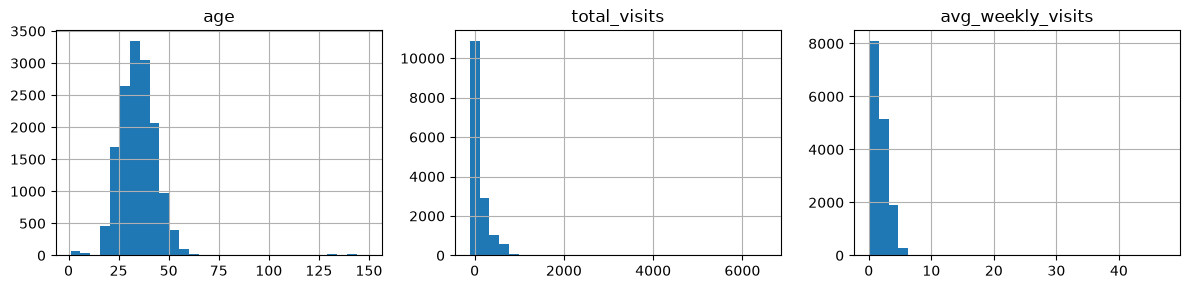

In [19]:
df[["age", "total_visits", "avg_weekly_visits"]].hist(
    bins=30, figsize=(12, 3), layout=(1, 3)
)
plt.tight_layout()
plt.show()

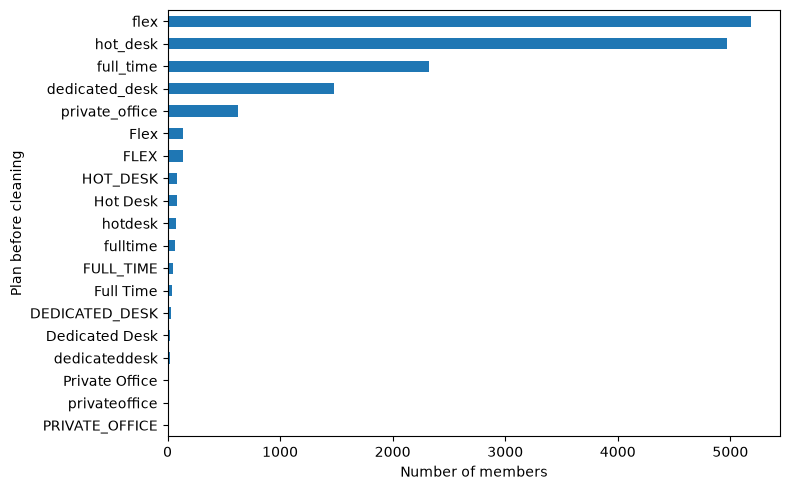

In [20]:
df["plan_tier"].value_counts().sort_values().plot(kind="barh", figsize=(8, 5))
plt.xlabel("Number of members")
plt.ylabel("Plan before cleaning")
plt.tight_layout()
plt.show()

## Basic cleaning
All changes below affect `df`. The original `df_raw` is preserved.

### Exact duplicates
Remove rows only when every column is identical to avoid counting the same member twice. Then check that member IDs are unique.

In [21]:
df = df_raw.copy()
rows_before = len(df)
df = df.drop_duplicates().copy()
missing_before_cleaning = df.isna().sum()

print("Rows removed:", rows_before - len(df))
print("Rows remaining:", len(df))
print("Repeated member IDs:", df["member_id"].duplicated().sum())

Rows removed: 15
Rows remaining: 15450
Repeated member IDs: 0


### Category labels
Remove surrounding spaces, use lowercase and merge clear aliases. This prevents spelling variants from becoming artificial categories. Missing values and other labels are preserved.

In [22]:
category_columns = ["gender", "country", "industry", "plan_tier"]
categories_before = df[category_columns].nunique()

for column in category_columns:
    df[column] = df[column].str.strip().str.lower()

In [23]:
df["gender"] = df["gender"].replace({
    "f": "female", "m": "male", "o": "other"
})

df["plan_tier"] = df["plan_tier"].replace({
    "hot desk": "hot_desk", "hotdesk": "hot_desk",
    "full time": "full_time", "fulltime": "full_time",
    "dedicated desk": "dedicated_desk", "dedicateddesk": "dedicated_desk",
    "private office": "private_office", "privateoffice": "private_office"
})

In [24]:
df["country"] = df["country"].replace({
    "pt": "portugal", "portucal": "portugal",
    "uk": "united kingdom", "gb": "united kingdom",
    "u.k.": "united kingdom",
    "de": "germany", "deutschland": "germany",
    "es": "spain", "espana": "spain", "españa": "spain",
    "fr": "france", "ie": "ireland",
    "nl": "netherlands", "the netherlands": "netherlands",
    "holland": "netherlands"
})

In [25]:
df["industry"] = df["industry"].replace({
    "it": "information technology",
    "design/creative": "design & creative",
    "design and creative": "design & creative",
    "marketing/pr": "marketing & pr",
    "marketing and pr": "marketing & pr",
    "realestate": "real estate", "real-estate": "real estate"
})

We keep `tech` separate because it is broader than information technology. We also keep `unknown`, `other` and `other (europe)` as distinct labels.

In [26]:
pd.DataFrame({
    "Categories before": categories_before,
    "Categories after": df[category_columns].nunique()
})

,Categories before,Categories after
gender,12,3
country,33,8
industry,43,12
plan_tier,19,5


In [27]:
df["plan_tier"].value_counts(dropna=False)

plan_tier
flex              5449
hot_desk          5212
full_time         2471
dedicated_desk    1549
private_office     664
NaN                105
Name: count, dtype: int64

### Revenue conversion
In this file, commas separate thousands and dots mark decimals. Remove euro symbols, commas and surrounding spaces, then convert to numbers for analysis. These formatting differences were not missing values. Check that conversion creates no new missing values. Negative values remain for later review.

In [28]:
revenue_text = df["lifetime_value"].str.replace("€", "", regex=False)
revenue_text = revenue_text.str.replace(",", "", regex=False).str.strip()
df["lifetime_value"] = pd.to_numeric(revenue_text, errors="raise")

print("Missing revenue values:", df["lifetime_value"].isna().sum())
print("Negative revenue values:", (df["lifetime_value"] < 0).sum())
print("New missing revenue values:",
      df["lifetime_value"].isna().sum() - missing_before_cleaning["lifetime_value"])

Missing revenue values: 1040
Negative revenue values: 82
New missing revenue values: 0


### Date conversion and interpretation
Both date formats were parsed above. Store the parsed dates in the working table.

The value `1970-01-01` looks like a placeholder, but its meaning is not documented. It does not prove that a membership is active. Keep it flagged and avoid using it to calculate duration. The guidelines define `membership_end` as the first end date, so later visits may follow a renewal.

In [29]:
date_columns = ["membership_start", "membership_end", "last_badge_swipe"]

for column in date_columns:
    df[column] = dates[column]

df[date_columns].dtypes

membership_start    datetime64[us]
membership_end      datetime64[us]
last_badge_swipe    datetime64[us]
dtype: object

In [30]:
end_1970 = df["membership_end"] == pd.Timestamp("1970-01-01")
end_before_start = (df["membership_end"] < df["membership_start"]) & ~end_1970
swipe_before_start = df["last_badge_swipe"] < df["membership_start"]

pd.Series({
    "End date equal to 1970-01-01": end_1970.sum(),
    "End before start, excluding 1970": end_before_start.sum(),
    "Last swipe before start": swipe_before_start.sum()
})

End date equal to 1970-01-01        3954
End before start, excluding 1970     152
Last swipe before start               94
dtype: int64

In [31]:
recency_to_end = (df["membership_end"] - df["last_badge_swipe"]).dt.days
print("Recency values matching membership end:",
      (df["days_since_last_visit"] == recency_to_end).sum())

recency_reference = df["last_badge_swipe"] + pd.to_timedelta(
    df["days_since_last_visit"], unit="D"
)
recency_reference.value_counts().head()

Recency values matching membership end: 9901


2024-01-01    3383
2023-12-31     263
2023-11-28      29
2023-11-30      28
2023-10-06      28
Name: count, dtype: int64

The implied reference date varies across members. Recency often matches the membership end rather than a single extraction date. Its definition needs confirmation before recalculating it.

### Service flags
The original `uses_print` values are only 0 and 1. Convert them to match the other service flags.

In [32]:
print("Print flag counts before conversion:", df["uses_print"].value_counts().to_dict())
df["uses_print"] = df["uses_print"].astype(bool)
print("Print flag counts after conversion:", df["uses_print"].value_counts().to_dict())
df.filter(like="uses_").dtypes

Print flag counts before conversion: {0: 10458, 1: 4992}
Print flag counts after conversion: {False: 10458, True: 4992}


uses_meeting_rooms    bool
uses_event_space      bool
uses_guest_passes     bool
uses_print            bool
uses_mail_handling    bool
uses_phone_booths     bool
uses_day_passes       bool
uses_storage          bool
uses_bike_locker      bool
dtype: object

### Check the basic conversions
At this stage only exact duplicate rows were removed. The format conversions should preserve missing values and all remaining records. Further treatments follow in the next section.

In [33]:
pd.Series({
    "Rows remaining": len(df),
    "Exact duplicate rows": df.duplicated().sum(),
    "Repeated member IDs": df["member_id"].duplicated().sum(),
    "Missing counts unchanged after conversions": df.isna().sum().equals(missing_before_cleaning)
})

Rows remaining                                15450
Exact duplicate rows                              0
Repeated member IDs                               0
Missing counts unchanged after conversions     True
dtype: object

In [34]:
numeric_columns = df.select_dtypes(include="number").columns
negatives = (df[numeric_columns] < 0).sum()
negatives[negatives > 0]

n_colleagues_on_account    565
days_since_last_visit       56
total_visits                42
meeting_room_hours          16
event_space_hours            8
guest_passes_issued          7
n_renewals                  66
lifetime_value              82
dtype: int64

## Agreed data quality treatments
Keep all remaining members. Store the basic cleaned data before applying the agreed rules.

In [35]:
df_basic = df.copy()
guest_missing_no_use = df["guest_passes_issued"].isna() & ~df["uses_guest_passes"]
meeting_missing_no_use = df["meeting_room_hours"].isna() & ~df["uses_meeting_rooms"]

### Age
Keep age 14. Our project rule treats ages below 10 or above 120 as unreliable for professional membership records. These are explicit assumptions, not universal age limits. Fill missing and invalid ages with the median of the remaining ages. The median is a simple estimate less sensitive to extremes than the mean. Imputation reduces variation and does not recover the true ages.

In [36]:
age_invalid = (df["age"] < 10) | (df["age"] > 120)
df["age"] = df["age"].mask(age_invalid)
age_imputed = df["age"].isna()
age_median = df["age"].median()
df["age"] = df["age"].fillna(age_median)

print("Invalid ages:", age_invalid.sum())
print("Originally missing ages after deduplication:", df_basic["age"].isna().sum())
print("Median age:", age_median)
print("Ages filled:", age_imputed.sum())
print("Missing ages after treatment:", df["age"].isna().sum())
print("Members aged 14 retained:", (df["age"] == 14).sum())

Invalid ages: 142
Originally missing ages after deduplication: 557
Median age: 34.0
Ages filled: 699
Missing ages after treatment: 0
Members aged 14 retained: 1


### Unknown categories
Use `unknown` for missing gender, country and plan labels instead of assigning an unsupported category. Keep these members and their other information. Unknown is distinct from other. These fields can describe clusters later; this does not decide which features will enter the clustering model.

In [37]:
description_columns = ["gender", "country", "plan_tier"]

for column in description_columns:
    df[column] = df[column].fillna("unknown")

pd.DataFrame({
    "Missing before": df_basic[description_columns].isna().sum(),
    "Unknown after": (df[description_columns] == "unknown").sum(),
    "Missing after": df[description_columns].isna().sum()
})

,Missing before,Unknown after,Missing after
gender,530,530,0
country,429,429,0
plan_tier,105,105,0


### Invalid counts and hours
Counts of people, visits, passes, renewals and hours of use cannot represent negative quantities here. Mark these cells as missing while keeping the members. A plan cannot provide more than seven days per week, so mark those cells as missing too. Negative revenue and recency need separate interpretation and remain unchanged.

In [38]:
negative_columns = [
    "n_colleagues_on_account", "total_visits", "meeting_room_hours",
    "event_space_hours", "guest_passes_issued", "n_renewals"
]
negative_counts_before = (df[negative_columns] < 0).sum()

for column in negative_columns:
    df[column] = df[column].mask(df[column] < 0)

invalid_plan_days = df["plan_days_per_week"] > 7
df["plan_days_per_week"] = df["plan_days_per_week"].mask(invalid_plan_days)

print("Invalid weekly plan days marked missing:", invalid_plan_days.sum())
print("Missing weekly plan days before:", df_basic["plan_days_per_week"].isna().sum())
print("Missing weekly plan days after:", df["plan_days_per_week"].isna().sum())
pd.DataFrame({
    "Negatives before": negative_counts_before,
    "Negatives after": (df[negative_columns] < 0).sum(),
    "Missing after this step": df[negative_columns].isna().sum()
})

Invalid weekly plan days marked missing: 54
Missing weekly plan days before: 0
Missing weekly plan days after: 54


,Negatives before,Negatives after,Missing after this step
n_colleagues_on_account,565,0,565
total_visits,42,0,42
meeting_room_hours,16,0,1311
event_space_hours,8,0,8
guest_passes_issued,7,0,1276
n_renewals,66,0,66


### Unknown membership end dates
Every end date equal to 1970-01-01 precedes its recorded membership start. It is not a reliable end date, so store it as NaT, a missing date. The original value remains in `df_raw` and `df_basic`. This does not tell us whether the member is active or inactive.

In [39]:
known_ends_before = df["membership_end"].notna().sum()
print("All 1970 ends precede membership start:",
      (df.loc[end_1970, "membership_end"] < df.loc[end_1970, "membership_start"]).all())
df["membership_end"] = df["membership_end"].mask(end_1970)

pd.Series({
    "End dates marked unknown": end_1970.sum(),
    "Known ends before": known_ends_before,
    "Known ends after": df["membership_end"].notna().sum(),
    "Missing ends after": df["membership_end"].isna().sum()
})

All 1970 ends precede membership start: True


End dates marked unknown     3954
Known ends before           15450
Known ends after            11496
Missing ends after           3954
dtype: int64

### Missing service quantities
Guest passes are passes issued by a member for visitors. Assume zero when the original quantity is missing and the usage flag is False. This is an imputation assumption, especially for meeting rooms where some flags conflict with recorded hours.

Keep missing quantities for True flags as NaN. True means the member used the service; it does not tell us the number of passes or hours. Invalid negative quantities remain missing. Preserve recorded positive hours and the original flags in the conflicting records.

In [40]:
df.loc[guest_missing_no_use, "guest_passes_issued"] = 0
df.loc[meeting_missing_no_use, "meeting_room_hours"] = 0

print("Missing guest pass quantities filled with zero:", guest_missing_no_use.sum())
print("Missing meeting hours filled with zero:", meeting_missing_no_use.sum())
service_checks = []
for quantity, flag in [("guest_passes_issued", "uses_guest_passes"),
                       ("meeting_room_hours", "uses_meeting_rooms")]:
    for used in [False, True]:
        before = df_basic.loc[df_basic[flag] == used, quantity]
        after = df.loc[df[flag] == used, quantity]
        service_checks.append({
            "Quantity": quantity, "Used": used,
            "Missing before": before.isna().sum(),
            "Missing after": after.isna().sum(),
            "Positive before": (before > 0).sum(),
            "Positive after": (after > 0).sum()
        })
pd.DataFrame(service_checks)

Missing guest pass quantities filled with zero: 1066
Missing meeting hours filled with zero: 902


,Quantity,Used,Missing before,Missing after,Positive before,Positive after
0,guest_passes_issued,False,1066,0,0,0
1,guest_passes_issued,True,203,210,2477,2477
2,meeting_room_hours,False,902,0,55,55
3,meeting_room_hours,True,393,409,4842,4842


### Unresolved data quality flags
The flags below refer to values before these treatments. No extra correction is made to visit discrepancies; the rule for negative values still applies. Their cause is unknown. Date conflicts remain unresolved, and future duration features must exclude affected intervals.

A zero revenue value together with recency 999 suggests a possible data quality pattern. It does not establish that the member is inactive or that the whole record is false. Keep both values unchanged. A cluster driven by these values could reflect data quality rather than a useful business segment. Compare results with and without this flagged group during modelling before deciding whether to exclude it.

In [41]:
visit_gap = df_basic["actual_visits_last_period"] - df_basic["total_visits"]
meeting_conflict = (~df_basic["uses_meeting_rooms"]) & (df_basic["meeting_room_hours"] > 0)

quality_flags = pd.DataFrame({
    "First end date unresolved (1970)": end_1970,
    "First end before start": end_before_start,
    "Last swipe before start": swipe_before_start,
    "Visits exceed total by one or two": visit_gap.between(1, 2),
    "Visits exceed total by more than two": visit_gap > 2,
    "Positive meeting hours with unused flag": meeting_conflict,
    "Zero revenue and recency 999": (df_basic["lifetime_value"] == 0) & (df_basic["days_since_last_visit"] == 999)
})
quality_flags.sum()

First end date unresolved (1970)           3954
First end before start                      152
Last swipe before start                      94
Visits exceed total by one or two           962
Visits exceed total by more than two        207
Positive meeting hours with unused flag      55
Zero revenue and recency 999               1296
dtype: int64

In [42]:
zero_999 = quality_flags["Zero revenue and recency 999"]
pd.Series({
    "Members flagged": zero_999.sum(),
    "Share of members (%)": round(100 * zero_999.mean(), 2),
    "Flagged members with positive visits": (zero_999 & (df_basic["total_visits"] > 0)).sum(),
    "Flagged members with positive renewals": (zero_999 & (df_basic["n_renewals"] > 0)).sum(),
    "Members retained": len(df)
})

Members flagged                            1296.00
Share of members (%)                          8.39
Flagged members with positive visits       1284.00
Flagged members with positive renewals      545.00
Members retained                          15450.00
dtype: float64

In [43]:
valid_visit_totals = df_basic["total_visits"] >= 0
visit_columns = ["total_visits", "actual_visits_last_period"]
pd.Series({
    "Positive meeting hours in conflicts preserved": df.loc[meeting_conflict, "meeting_room_hours"].equals(df_basic.loc[meeting_conflict, "meeting_room_hours"]),
    "Original service flags preserved": df.filter(like="uses_").equals(df_basic.filter(like="uses_")),
    "Nonnegative visit counts preserved": (df.loc[valid_visit_totals, visit_columns] == df_basic.loc[valid_visit_totals, visit_columns]).all().all(),
    "Revenue and recency preserved": df[["lifetime_value", "days_since_last_visit"]].equals(df_basic[["lifetime_value", "days_since_last_visit"]]),
    "Start and swipe dates preserved": df[["membership_start", "last_badge_swipe"]].equals(df_basic[["membership_start", "last_badge_swipe"]]),
    "Other end dates preserved": df.loc[~end_1970, "membership_end"].equals(df_basic.loc[~end_1970, "membership_end"])
})

Positive meeting hours in conflicts preserved    True
Original service flags preserved                 True
Nonnegative visit counts preserved               True
Revenue and recency preserved                    True
Start and swipe dates preserved                  True
Other end dates preserved                        True
dtype: bool

### Check the treatments
Confirm that all members remain and compare missing values before and after the agreed treatments. Missing values can increase when unreliable measurements or dates are identified. Original values remain available in the saved copies. Quality flags and imputation masks are kept separately from the dataset.

In [44]:
print("Members before treatments:", len(df_basic))
print("Members after treatments:", len(df))
missing_comparison = pd.DataFrame({
    "Before agreed treatments": df_basic.isna().sum(),
    "After agreed treatments": df.isna().sum()
})
missing_comparison[(missing_comparison > 0).any(axis=1)]

Members before treatments: 15450
Members after treatments: 15450


,Before agreed treatments,After agreed treatments
age,557,0
gender,530,0
country,429,0
n_colleagues_on_account,0,565
plan_tier,105,0
plan_days_per_week,0,54
membership_end,0,3954
total_visits,0,42
meeting_room_hours,1295,409
event_space_hours,0,8


## Distributions, relationships and recorded trends
Explore usage, economic value, plans and reported service use. These analyses use separate views and summaries. All members remain in `df`, including the flagged zero revenue and recency 999 group. No clustering or final model preparation is performed here.

### Numeric distributions
Compare counts, missing values, zeros, medians and upper percentiles. The full maxima remain visible here even when a later chart uses a closer view. Different metrics have different numbers of available observations.

In [45]:
summary_metrics = [
    "avg_weekly_visits", "total_visits", "actual_visits_last_period",
    "meeting_room_hours", "event_space_hours", "guest_passes_issued",
    "n_renewals", "lifetime_value"
]
metric_summary = df[summary_metrics].describe(percentiles=[0.5, 0.95, 0.99]).T
metric_summary["Missing"] = df[summary_metrics].isna().sum()
metric_summary["Zeros"] = (df[summary_metrics] == 0).sum()
metric_summary[["count", "Missing", "Zeros", "min", "mean", "50%", "95%", "99%", "max"]].round(2)

,count,Missing,Zeros,min,mean,50%,95%,99%,max
avg_weekly_visits,15450.0,0,14,0.00,1.78,1.42,4.39,5.32,47.4
total_visits,15408.0,42,109,0.00,110.78,35.00,523.00,693.93,6530.0
actual_visits_last_period,15450.0,0,294,0.00,13.80,10.00,38.00,43.51,60.0
meeting_room_hours,15041.0,409,10144,0.00,31.16,0.00,139.40,319.92,41220.0
event_space_hours,15442.0,8,13683,0.00,5.12,0.00,29.50,127.44,602.8
guest_passes_issued,15240.0,210,12763,0.00,5.74,0.00,38.05,115.00,589.0
n_renewals,15384.0,66,7742,0.00,1.02,0.00,4.00,5.00,6.0
lifetime_value,14410.0,1040,1742,-13440.24,6398.77,825.12,15340.76,25665.03,3371260.0


### Economic value and extreme values
For economic comparisons, use observed nonnegative lifetime values. Negative values need interpretation and are excluded only from this analytical view. Keep all zeros, including the flagged group. This does not change revenue in `df`.

In [46]:
revenue_data = df.loc[df["lifetime_value"].notna() & (df["lifetime_value"] >= 0)].copy()
pd.Series({
    "All members": len(df),
    "Observed nonnegative revenue": len(revenue_data),
    "Missing revenue excluded from this view": df["lifetime_value"].isna().sum(),
    "Negative revenue excluded from this view": (df["lifetime_value"] < 0).sum(),
    "Zero revenue retained": (revenue_data["lifetime_value"] == 0).sum()
})

All members                                 15450
Observed nonnegative revenue                14328
Missing revenue excluded from this view      1040
Negative revenue excluded from this view       82
Zero revenue retained                        1742
dtype: int64

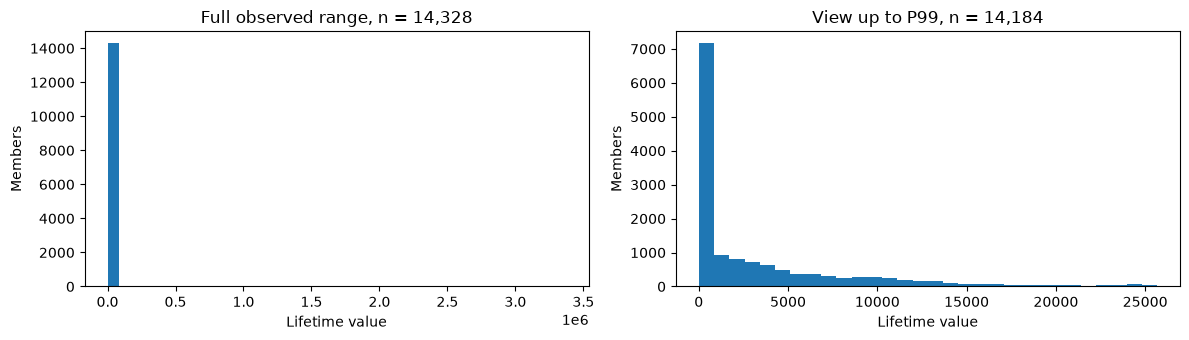

Upper limit of the closer view: 25680.23
Members outside the closer view, still retained: 144


In [47]:
revenue_limit = revenue_data["lifetime_value"].quantile(0.99)
revenue_zoom = revenue_data.loc[revenue_data["lifetime_value"] <= revenue_limit]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
revenue_data["lifetime_value"].plot.hist(bins=40, ax=axes[0])
axes[0].set_title(f"Full observed range, n = {len(revenue_data):,}")
revenue_zoom["lifetime_value"].plot.hist(bins=30, ax=axes[1])
axes[1].set_title(f"View up to P99, n = {len(revenue_zoom):,}")
for ax in axes:
    ax.set_xlabel("Lifetime value")
    ax.set_ylabel("Members")
plt.tight_layout()
plt.show()
print("Upper limit of the closer view:", round(revenue_limit, 2))
print("Members outside the closer view, still retained:", len(revenue_data) - len(revenue_zoom))

Lifetime value is strongly skewed: a few very large values stretch the full range. The closer view shows the distribution for most members without deleting the upper tail. High values may include valuable customers as well as data problems, so this chart alone does not justify removal.

### Usage and value by plan
Compare medians because means are sensitive to extreme values, and include revenue quartiles to show variation within each plan. Show group sizes and revenue coverage. Usage summaries use available observations; revenue summaries use the nonnegative analytical view above, including zero revenue. Missing revenue and negative revenue excluded from this view are reported separately. Unknown remains a separate descriptive group.

In [48]:
plan_order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office", "unknown"]
plan_summary = df.groupby("plan_tier")[["avg_weekly_visits", "actual_visits_last_period"]].median()
plan_summary["Members"] = df.groupby("plan_tier").size()
plan_summary["Revenue observations"] = revenue_data.groupby("plan_tier")["lifetime_value"].count()
plan_summary["Median lifetime value"] = revenue_data.groupby("plan_tier")["lifetime_value"].median()
plan_summary["Revenue P25"] = revenue_data.groupby("plan_tier")["lifetime_value"].quantile(0.25)
plan_summary["Revenue P75"] = revenue_data.groupby("plan_tier")["lifetime_value"].quantile(0.75)
plan_summary["Revenue missing (%)"] = df["lifetime_value"].isna().groupby(df["plan_tier"]).mean() * 100
plan_summary["Negative revenue excluded"] = (df["lifetime_value"] < 0).groupby(df["plan_tier"]).sum()
plan_summary = plan_summary.reindex(plan_order)
plan_summary.round(2)

,avg_weekly_visits,actual_visits_last_period,Members,Revenue observations,Median lifetime value,Revenue P25,Revenue P75,Revenue missing (%),Negative revenue excluded
plan_tier,,,,,,,,,
hot_desk,0.96,7.0,5212,4935,320.93,192.44,1124.00,4.66,34
flex,1.89,14.0,5449,5067,1200.80,310.55,3556.89,6.61,22
dedicated_desk,3.86,31.0,1549,1388,10378.74,7142.88,12921.95,9.75,10
full_time,1.61,13.0,2471,2261,4660.73,513.83,8289.98,7.89,15
private_office,1.04,9.0,664,591,20000.08,13528.40,24286.28,10.84,1
unknown,3.98,31.0,105,86,10190.96,0.00,16826.20,18.10,0


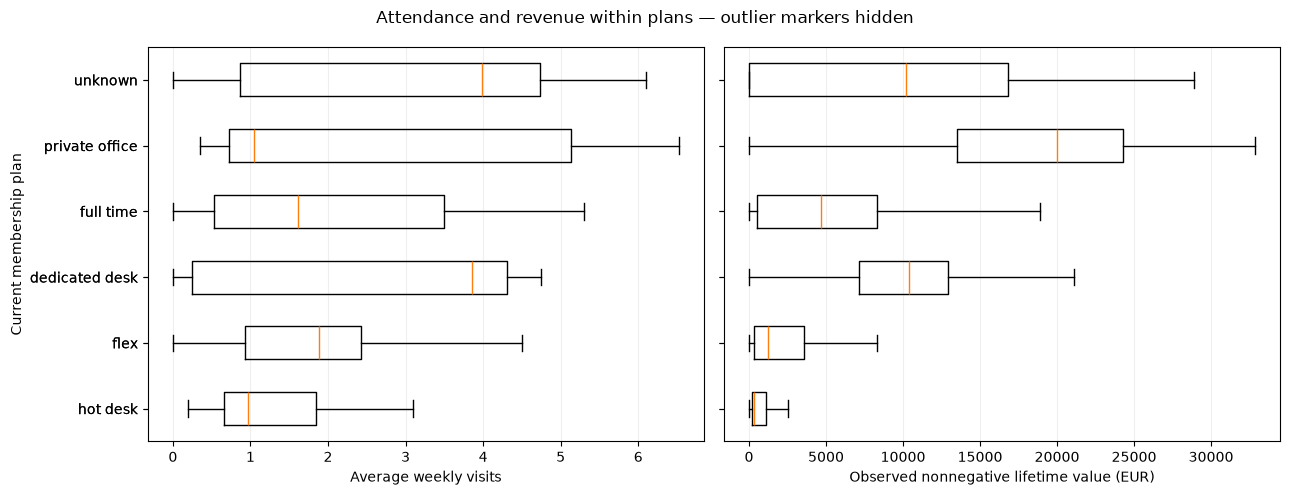

In [49]:
plan_labels = [plan.replace("_", " ") for plan in plan_order]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, data, column, label in [
    (axes[0], df, "avg_weekly_visits", "Average weekly visits"),
    (axes[1], revenue_data, "lifetime_value", "Observed nonnegative lifetime value (EUR)")
]:
    values_by_plan = [
        data.loc[data["plan_tier"] == plan, column].dropna()
        for plan in plan_order
    ]
    ax.boxplot(
        values_by_plan, orientation="horizontal",
        tick_labels=plan_labels, showfliers=False
    )
    ax.set_xlabel(label)
    ax.grid(axis="x", alpha=0.2)

axes[0].set_ylabel("Current membership plan")
fig.suptitle("Attendance and revenue within plans — outlier markers hidden")
plt.tight_layout()
plt.show()

The box spans the 25th to 75th percentiles, and its central line is the median. Whiskers extend to the most extreme observations within 1.5 times the interquartile range of the box. Outlier markers are hidden for readability, but all available observations contribute to these statistics. Full revenue extremes remain visible in the earlier distribution analysis. This display choice does not remove members or decide their treatment for modelling.

Private-office members have the highest median observed nonnegative lifetime value (about EUR 20,000), while dedicated-desk members have higher median weekly attendance (3.86 visits, compared with 1.04 for private office). There is also substantial variation within each plan. Value and attendance therefore describe different aspects of customers. These are associations, not effects caused by the plan. Lifetime value covers potentially different membership lengths, and the current plan may not describe the entire history. The 105 unknown-plan members remain visible, with their revenue coverage reported above.

### Relationship between visits and value
Use members with both nonnegative revenue and known total visits. Compare the full scatter with a closer view of the same pairs. Axis limits only change the display. They do not remove members.

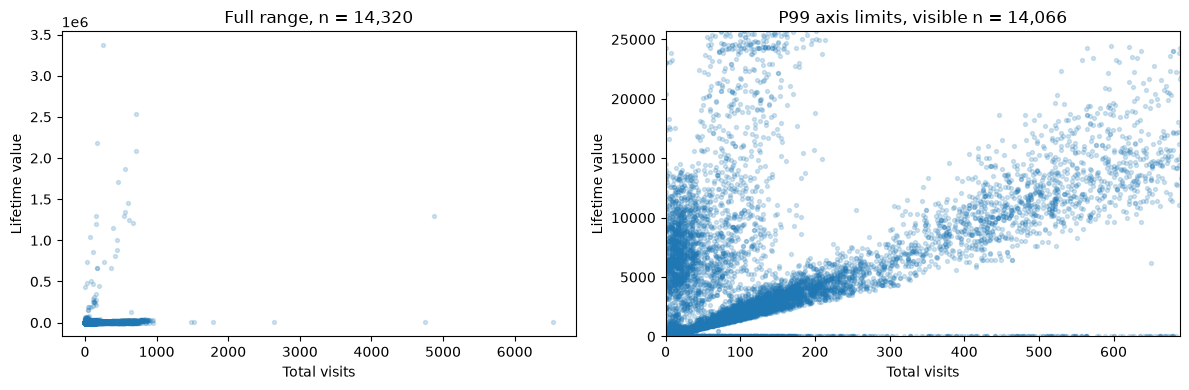

Members without an analytical pair: 1130
Pairs outside the closer view: 254
Full sample Pearson correlation: 0.14


In [50]:
visit_value_pairs = revenue_data[["total_visits", "lifetime_value"]].dropna()
visits_limit = visit_value_pairs["total_visits"].quantile(0.99)
value_limit = visit_value_pairs["lifetime_value"].quantile(0.99)
inside_view = (visit_value_pairs["total_visits"] <= visits_limit) & (visit_value_pairs["lifetime_value"] <= value_limit)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax in axes:
    ax.scatter(visit_value_pairs["total_visits"], visit_value_pairs["lifetime_value"], alpha=0.2, s=8)
    ax.set_xlabel("Total visits")
    ax.set_ylabel("Lifetime value")
axes[0].set_title(f"Full range, n = {len(visit_value_pairs):,}")
axes[1].set_xlim(0, visits_limit)
axes[1].set_ylim(0, value_limit)
axes[1].set_title(f"P99 axis limits, visible n = {inside_view.sum():,}")
plt.tight_layout()
plt.show()
print("Members without an analytical pair:", len(df) - len(visit_value_pairs))
print("Pairs outside the closer view:", (~inside_view).sum())
print("Full sample Pearson correlation:", round(visit_value_pairs.corr().iloc[0, 1], 3))

The closer scatter makes the association easier to see, while the full view reveals the extremes. Pearson correlation describes a linear relationship and is sensitive to extreme values. Compare it with the plots. The matrix below uses available pairs, so sample sizes differ. It does not demonstrate causation.

In [51]:
correlation_columns = [
    "total_visits", "avg_weekly_visits", "actual_visits_last_period",
    "meeting_room_hours", "n_renewals", "lifetime_value"
]
correlation_data = df[correlation_columns].copy()
correlation_data["lifetime_value"] = correlation_data["lifetime_value"].mask(correlation_data["lifetime_value"] < 0)
correlation_data.corr().round(2)

,total_visits,avg_weekly_visits,actual_visits_last_period,meeting_room_hours,n_renewals,lifetime_value
total_visits,1.00,0.66,0.76,0.06,0.36,0.14
avg_weekly_visits,0.66,1.00,0.66,0.02,0.22,0.08
actual_visits_last_period,0.76,0.66,1.00,0.04,0.31,0.09
meeting_room_hours,0.06,0.02,0.04,1.00,0.03,0.08
n_renewals,0.36,0.22,0.31,0.03,1.00,0.07
lifetime_value,0.14,0.08,0.09,0.08,0.07,1.00


### Individual and team accounts
Compare group sizes and medians, then service use percentages. Percentages avoid confusing the larger individual group with higher propensity to use an extra. Service flags remain unchanged, including the recorded meeting room conflicts.

In [52]:
account_summary = df.groupby("is_team_account")[["avg_weekly_visits", "actual_visits_last_period"]].median()
account_summary["Members"] = df.groupby("is_team_account").size()
account_summary["Revenue observations"] = revenue_data.groupby("is_team_account")["lifetime_value"].count()
account_summary["Median lifetime value"] = revenue_data.groupby("is_team_account")["lifetime_value"].median()
account_summary.rename(index={False: "Individual", True: "Team"}).round(2)

,avg_weekly_visits,actual_visits_last_period,Members,Revenue observations,Median lifetime value
is_team_account,,,,,
Individual,1.42,10.0,11100,10318,835.59
Team,1.45,11.0,4350,4010,913.79


### Account type within each plan
The overall account comparison may conceal differences in plan composition. Compare individual and team accounts within each current plan. Attendance uses all available observations; revenue uses the same nonnegative view as the other economic comparisons. Report revenue coverage for each subgroup. This remains descriptive and does not control for membership duration or history.

In [53]:
plan_account_summary = df.groupby(["plan_tier", "is_team_account"]).agg(
    members=("member_id", "size"),
    median_weekly_visits=("avg_weekly_visits", "median")
)
plan_account_revenue = revenue_data.groupby(["plan_tier", "is_team_account"])["lifetime_value"]
plan_account_summary["revenue_observations"] = plan_account_revenue.count()
plan_account_summary["median_nonnegative_revenue"] = plan_account_revenue.median()
plan_account_summary["revenue_coverage_pct"] = (
    100 * plan_account_summary["revenue_observations"] / plan_account_summary["members"]
)
plan_account_summary = plan_account_summary.reindex(plan_order, level="plan_tier")
plan_account_summary.rename(
    index={False: "Individual", True: "Team"}, level="is_team_account"
).round(2)

members  median_weekly_visits  \
plan_tier      is_team_account                                  
hot_desk       Individual          3749                  0.96   
               Team                1463                  0.97   
flex           Individual          3879                  1.88   
               Team                1570                  1.91   
dedicated_desk Individual          1121                  3.88   
               Team                 428                  3.74   
full_time      Individual          1808                  1.57   
               Team                 663                  1.92   
private_office Individual           457                  1.05   
               Team                 207                  1.01   
unknown        Individual            86                  3.82   
               Team                  19                  4.62   

                                revenue_observations  \
plan_tier      is_team_account                         
hot_desk       Individual                       3556   
               Team                             1379   
flex           Individual                       3607   
               Team                             1460   
dedicated_desk Individual                       1011   
               Team                              377   
full_time      Individual                       1665   
               Team                              596   
private_office Individual                        407   
               Team                              184   
unknown        Individual                         72   
               Team                               14   

                                median_nonnegative_revenue  \
plan_tier      is_team_account                               
hot_desk       Individual                           320.37   
               Team                                 323.45   
flex           Individual                          1198.51   
               Team                                1212.18   
dedicated_desk Individual                         10359.13   
               Team                               10455.03   
full_time      Individual                          4396.21   
               Team                                5150.49   
private_office Individual                         19821.22   
               Team                               20635.16   
unknown        Individual                         10091.56   
               Team                               13777.28   

                                revenue_coverage_pct  
plan_tier      is_team_account                        
hot_desk       Individual                      94.85  
               Team                            94.26  
flex           Individual                      92.99  
               Team                            92.99  
dedicated_desk Individual                      90.19  
               Team                            88.08  
full_time      Individual                      92.09  
               Team                            89.89  
private_office Individual                      89.06  
               Team                            88.89  
unknown        Individual                      83.72  
               Team                            73.68

The high revenue and lower median attendance of private-office members are visible among both individual and team accounts. Account type alone therefore does not explain the descriptive contrast with dedicated desks. Subgroup sizes and revenue coverage differ, particularly in the small unknown-plan group; the table is not evidence of statistically significant or causal differences.

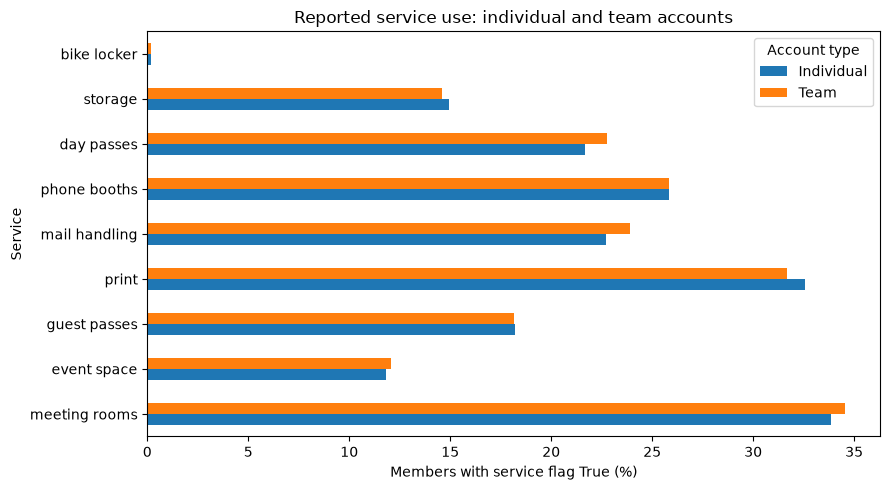

Account sample sizes: {'Individual': 11100, 'Team': 4350}


is_team_account,Individual,Team
meeting rooms,33.83,34.55
event space,11.83,12.07
guest passes,18.22,18.14
print,32.56,31.68
mail handling,22.71,23.89
phone booths,25.82,25.84
day passes,21.65,22.78
storage,14.94,14.60
bike locker,0.17,0.16


In [54]:
service_columns = df.filter(like="uses_").columns
service_rates = df.groupby("is_team_account")[service_columns].mean().T * 100
service_rates = service_rates.rename(columns={False: "Individual", True: "Team"})
service_rates.index = service_rates.index.str.replace("uses_", "", regex=False).str.replace("_", " ", regex=False)
service_rates.plot.barh(figsize=(9, 5))
plt.xlabel("Members with service flag True (%)")
plt.ylabel("Service")
plt.title("Reported service use: individual and team accounts")
plt.legend(title="Account type")
plt.tight_layout()
plt.show()
print("Account sample sizes:", account_summary["Members"].rename(index={False: "Individual", True: "Team"}).to_dict())
service_rates.round(2)

The two account types have similar median attendance and reported service use percentages. Account type alone does not show a strong descriptive separation here. Rare services such as bike lockers should not be interpreted as broad customer patterns. The flags describe whether an extra was used, not its intensity.

### Reported service use by current plan
Compare meeting rooms, mail handling and day passes, which describe different service needs. Each percentage is the number of True flags divided by all members in that plan. A member may use several services, so percentages do not sum to 100%.

The flags indicate whether a service was ever used, whereas the plan is the current tier. These are recorded usage proportions, not quantities consumed or causal effects of the plan. The 55 meeting-room flag/hour conflicts remain unresolved; this comparison uses the original flags.

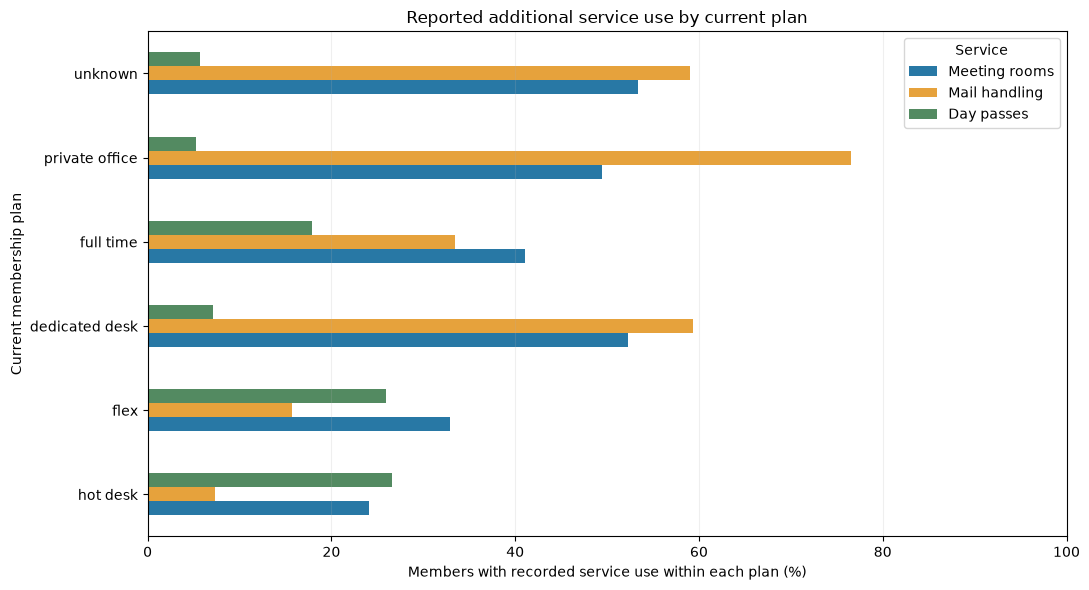

,Meeting rooms,Mail handling,Day passes
plan_tier,,,
hot_desk,24.0,7.4,26.6
flex,33.0,15.8,25.9
dedicated_desk,52.2,59.4,7.2
full_time,41.1,33.5,17.9
private_office,49.4,76.5,5.3
unknown,53.3,59.0,5.7


In [55]:
plan_service_columns = ["uses_meeting_rooms", "uses_mail_handling", "uses_day_passes"]
plan_service_rates = (
    df.groupby("plan_tier")[plan_service_columns].mean().mul(100)
    .reindex(plan_order)
    .rename(columns={
        "uses_meeting_rooms": "Meeting rooms",
        "uses_mail_handling": "Mail handling",
        "uses_day_passes": "Day passes"
    })
)

ax = plan_service_rates.rename(index=lambda value: value.replace("_", " ")).plot.barh(
    figsize=(11, 6), color=["#2878A5", "#E6A23C", "#538A61"]
)
ax.set_xlabel("Members with recorded service use within each plan (%)")
ax.set_ylabel("Current membership plan")
ax.set_xlim(0, 100)
ax.set_title("Reported additional service use by current plan")
ax.grid(axis="x", alpha=0.2)
ax.legend(title="Service")
plt.tight_layout()
plt.show()

plan_service_rates.round(1)

Recorded mail-handling use is much more common among private-office members (76.5%) than hot-desk members (7.4%). Day-pass use shows the opposite pattern: 5.3% versus 26.6%. This motivates exploring business-support services and flexible access as possible differentiators of member needs. These associations do not by themselves establish customer segments.

### Recorded membership starts over time
Count the first membership starts represented in the dataset. This is not a verified time series of acquisitions, revenue or current activity. Dates have not been reconstructed from unresolved end dates.

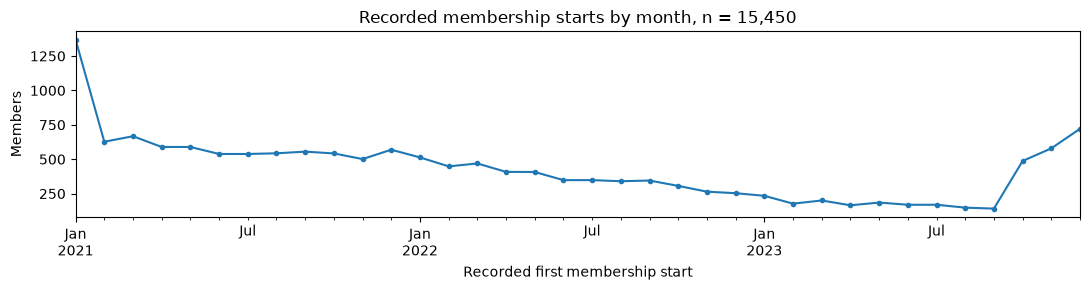

Recorded starts on 2021-01-01: 597


membership_start
2021    7626
2022    4449
2023    3375
Name: Members, dtype: int64

In [56]:
monthly_starts = df.groupby(df["membership_start"].dt.to_period("M")).size()
monthly_starts.index = monthly_starts.index.to_timestamp()
monthly_starts.plot(figsize=(11, 3), marker="o", markersize=3)
plt.xlabel("Recorded first membership start")
plt.ylabel("Members")
plt.title(f"Recorded membership starts by month, n = {monthly_starts.sum():,}")
plt.tight_layout()
plt.show()
print("Recorded starts on 2021-01-01:", (df["membership_start"] == pd.Timestamp("2021-01-01")).sum())
df.groupby(df["membership_start"].dt.year).size().rename("Members")

Recorded starts are concentrated in 2021, with a separate increase in late 2023. The unusually large count on the first day of 2021 may reflect a recording or observation boundary effect. Its cause is unknown, so the dates are preserved. These counts do not establish business growth or decline.

### Sensitivity to the flagged revenue pattern
Compare value summaries with and without the zero revenue and recency 999 group in a temporary view. This evaluates how the flagged data pattern affects the EDA. It does not remove the group or validate an exclusion rule.

In [57]:
revenue_without_flagged = revenue_data.loc[~zero_999]
value_sensitivity = pd.DataFrame({
    "Flagged group included": revenue_data["lifetime_value"].agg(["count", "median", "mean"]),
    "Flagged group omitted only from this view": revenue_without_flagged["lifetime_value"].agg(["count", "median", "mean"])
})
value_sensitivity.round(2)

,Flagged group included,Flagged group omitted only from this view
count,14328.00,13032.00
median,859.22,1460.02
mean,6447.52,7088.71


### Main findings from these comparisons
Value and attendance differ across plans, but do not follow the same ordering, and members within a plan vary substantially. Individual and team accounts show similar overall reported service use, while service use differs across current plans. Extreme values and the flagged revenue pattern materially affect numeric summaries. These findings motivate careful feature selection and business interpretation; they are not discovered clusters.

## Feature engineering: Plan utilization rate

Divide actual visits by entitled visits in the last membership period. For example, 8 visits out of 20 entitled visits gives a ratio of 0.40, or 40%. Both variables refer to the same last period in the data dictionary; this is not necessarily a calendar month.

Calculate a ratio only for positive allowances and nonnegative actual visits. Invalid or missing inputs leave the ratio undefined, while the member remains in `df`. Ratios are not capped: observations above 100% would need investigation. Store the ratio as a fraction and multiply by 100 for percentage displays.

In [58]:
# Only positive allowances and nonnegative visits define this ratio.
utilization_available = (
    (df["entitled_visits_last_period"] > 0)
    & (df["actual_visits_last_period"] >= 0)
)
valid_entitlement = df["entitled_visits_last_period"].where(utilization_available)

# Calculate utilization for the last membership period.
df["utilization_rate"] = (
    df["actual_visits_last_period"] / valid_entitlement
)

df[[
    "actual_visits_last_period",
    "entitled_visits_last_period",
    "utilization_rate"
]].head()

,actual_visits_last_period,entitled_visits_last_period,utilization_rate
0,22,26.09,0.843235
1,1,10.68,0.093633
2,2,26.09,0.076658
3,9,18.74,0.480256
4,3,17.39,0.172513


In [59]:
print("Members:", len(df))
print("Members with a calculated utilization rate:", df["utilization_rate"].notna().sum())
print("Members without a calculated utilization rate:", df["utilization_rate"].isna().sum())
print("Members with utilization above 100%:", (df["utilization_rate"] > 1).sum())
print("Zero allowance with positive visits:",
      ((df["entitled_visits_last_period"] == 0) & (df["actual_visits_last_period"] > 0)).sum())
print("Zero allowance and zero visits:",
      ((df["entitled_visits_last_period"] == 0) & (df["actual_visits_last_period"] == 0)).sum())
print("Known zero utilization with positive allowance:", (df["utilization_rate"] == 0).sum())

# Multiply by 100 for percentage summaries; count remains a member count.
utilization_summary = (df["utilization_rate"] * 100).describe()
utilization_summary.round(2)

Members: 15450
Members with a calculated utilization rate: 15440
Members without a calculated utilization rate: 10
Members with utilization above 100%: 0
Zero allowance with positive visits: 8
Zero allowance and zero visits: 2
Known zero utilization with positive allowance: 292


count    15440.00
mean        51.75
std         31.22
min          0.00
25%         23.90
50%         51.75
75%         80.49
max        100.00
Name: utilization_rate, dtype: float64

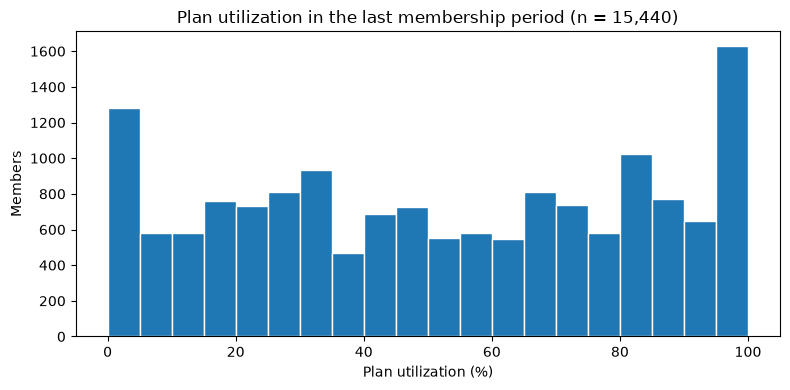

In [60]:
utilization_percent = df["utilization_rate"] * 100

utilization_percent.plot.hist(
    bins=20,
    figsize=(8, 4),
    edgecolor="white"
)

plt.xlabel("Plan utilization (%)")
plt.ylabel("Members")
plt.title(
    f"Plan utilization in the last membership period "
    f"(n = {utilization_percent.count():,})"
)

plt.tight_layout()
plt.show()

### Interpretation and relevance for segmentation

Across the 15,440 calculated ratios, median utilization is 51.75%, and the middle half lies between 23.90% and 80.49%. Ten members have zero allowances: eight with positive visits and two with zero visits. All ten ratios remain undefined. In contrast, the 292 members with zero visits and positive allowances have a known utilization of 0%.

This feature may distinguish low from high plan utilization, but does not establish dissatisfaction or churn. It measures use of entitled visits, not occupancy of the coworking space or the value of every service received. Last membership periods may cover different dates. `avg_weekly_visits` refers to the whole membership, so the time horizon differs. Assess the ratio alongside its source variables and other attendance measures to avoid redundant weighting.

### Utilization within current plans
First calculate each member's ratio, then summarise these ratios by current plan. Dividing group-level medians would answer a different question. Show coverage and quartiles so that differences within a plan remain visible. All members are retained; summaries and plots use calculated ratios only.

In [61]:
utilization_by_plan = df.groupby("plan_tier").agg(
    members=("member_id", "size"),
    calculated_ratios=("utilization_rate", "count"),
    median_utilization_pct=("utilization_rate", lambda values: 100 * values.median()),
    q25_utilization_pct=("utilization_rate", lambda values: 100 * values.quantile(0.25)),
    q75_utilization_pct=("utilization_rate", lambda values: 100 * values.quantile(0.75))
).reindex(plan_order)
utilization_by_plan["unknown_ratios"] = (
    utilization_by_plan["members"] - utilization_by_plan["calculated_ratios"]
)
utilization_by_plan.round(2)

,members,calculated_ratios,median_utilization_pct,q25_utilization_pct,q75_utilization_pct,unknown_ratios
plan_tier,,,,,,
hot_desk,5212,5209,46.46,31.06,86.26,3
flex,5449,5446,57.49,30.66,80.49,3
dedicated_desk,1549,1549,73.60,4.60,87.40,0
full_time,2471,2468,33.30,9.20,69.00,3
private_office,664,663,14.79,9.86,70.64,1
unknown,105,105,67.36,11.50,80.50,0


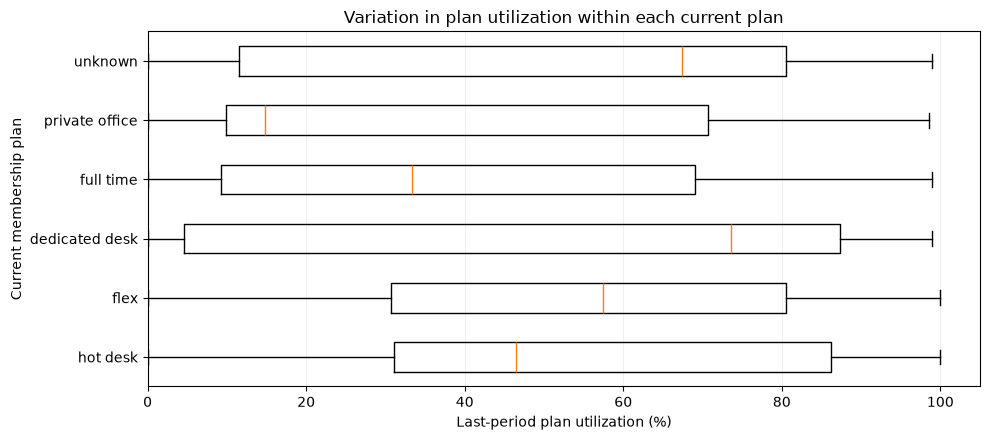

In [62]:
utilization_groups = [
    df.loc[df["plan_tier"] == plan, "utilization_rate"].dropna().mul(100)
    for plan in plan_order
]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot(utilization_groups, orientation="horizontal", tick_labels=plan_labels)
ax.set_xlabel("Last-period plan utilization (%)")
ax.set_ylabel("Current membership plan")
ax.set_title("Variation in plan utilization within each current plan")
ax.set_xlim(left=0)
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

Dedicated-desk members have median utilization of 73.60%, compared with 14.79% for private-office members. Combined with the earlier nonnegative revenue comparison, this suggests investigating high-value members whose needs may extend beyond frequent attendance. The wide distributions within plans show that a plan label alone cannot describe every member. Membership history and the unresolved quality flags still need consideration before interpreting these patterns as final customer groups.

### Variety of services used

Count the nine service flags marked True for each member. This measures reported service variety, not frequency or intensity, and may distinguish basic from broader service use.

In [63]:
# Select the original service-use flags.
service_columns = df.filter(like="uses_").columns

# Count how many services are marked True for each member.
df["n_services_used"] = df[service_columns].sum(axis=1)

print("Number of service flags:", len(service_columns))

df[
    list(service_columns) + ["n_services_used"]
].head()

Number of service flags: 9


,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_services_used
0,False,False,True,False,False,True,True,False,False,3
1,False,False,False,False,True,False,False,False,False,1
2,False,False,False,False,False,False,False,False,False,0
3,False,False,False,False,False,False,False,False,False,0
4,False,False,False,False,False,False,True,False,False,1


In [64]:
service_summary = pd.Series({
    "Members": len(df),
    "Members with no reported services": (
        df["n_services_used"] == 0
    ).sum(),
    "Members with no reported services (%)": (
        df["n_services_used"] == 0
    ).mean() * 100,
    "Mean number of services": df["n_services_used"].mean(),
    "Median number of services": df["n_services_used"].median(),
    "Maximum number of services": df["n_services_used"].max()
})

service_summary.round(2)

Members                                  15450.00
Members with no reported services         3087.00
Members with no reported services (%)       19.98
Mean number of services                      1.82
Median number of services                    1.00
Maximum number of services                   8.00
dtype: float64

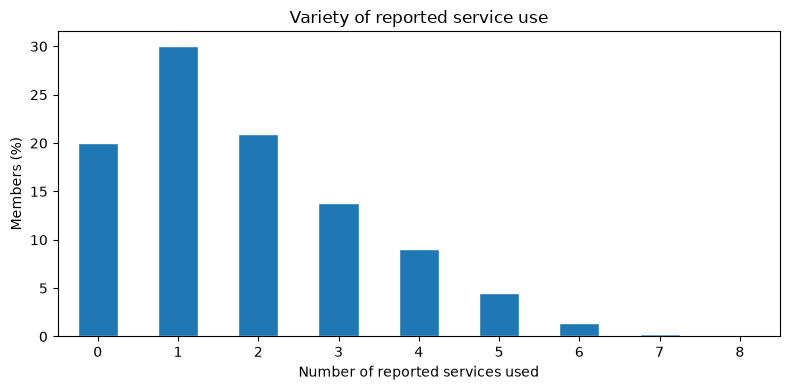

In [65]:
# Calculate the percentage of members for each service count.
service_distribution = (
    df["n_services_used"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

service_distribution.plot.bar(
    figsize=(8, 4),
    edgecolor="white"
)

plt.xlabel("Number of reported services used")
plt.ylabel("Members (%)")
plt.title("Variety of reported service use")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [66]:
# Compare plan utilization across different service counts.
service_utilization_summary = (
    df.groupby("n_services_used")
    .agg(
        members=("member_id", "size"),
        members_with_utilization=("utilization_rate", "count"),
        median_utilization=("utilization_rate", "median")
    )
)

# Express utilization as a percentage.
service_utilization_summary["median_utilization_pct"] = (
    service_utilization_summary["median_utilization"] * 100
)

service_utilization_summary[[
    "members",
    "members_with_utilization",
    "median_utilization_pct"
]].round(2)

,members,members_with_utilization,median_utilization_pct
n_services_used,,,
0,3087,3087,37.20
1,4643,4638,42.06
2,3236,3233,57.49
3,2139,2137,65.16
4,1395,1395,68.99
5,690,690,66.70
6,223,223,73.60
7,34,34,74.91
8,3,3,38.33


### Interpretation and limitations
About 20% of members have no reported services. Median plan utilization generally rises with service variety, although the pattern is not strictly increasing. The eight-service group contains only three members, so its lower median should be interpreted cautiously.

All services receive equal weight and existing flag inconsistencies remain. Flags describe whether services were ever used; utilization covers the last membership period. These measures suggest hypotheses, not confirmed clusters or causation. Assess the service count alongside individual flags to avoid redundant weighting.

## Candidate features and redundancy

### Relationships including the engineered features

The earlier Pearson matrix describes linear relationships among original variables. Here, Spearman correlation compares ranks and captures monotonic relationships, including those involving `utilization_rate` and `n_services_used`. It is useful for these skewed distributions, but neither proves independence when near zero nor resolves data quality problems.

Use all retained members when the required measurements are available. For pairs involving revenue, use only observed nonnegative revenue, consistently with the economic comparisons above. Mask negative revenue only in this temporary table: members can still contribute to other pairs. Correlations use pairwise complete observations; the second table reports the exact sample size for selected relationships. Zeros, including the zero/999 group, remain included.

In [67]:
candidate_numeric_columns = [
    "lifetime_value", "total_visits", "avg_weekly_visits",
    "actual_visits_last_period", "entitled_visits_last_period",
    "utilization_rate", "n_services_used", "n_renewals"
]
candidate_relationship_data = df[
    candidate_numeric_columns + list(service_columns)
].copy()
# Apply the economic-view rule only to the revenue column in this copy.
candidate_relationship_data["lifetime_value"] = (
    candidate_relationship_data["lifetime_value"].where(
        candidate_relationship_data["lifetime_value"] >= 0
    )
)
candidate_spearman = candidate_relationship_data[
    candidate_numeric_columns
].corr(method="spearman")
candidate_spearman.round(3)

,lifetime_value,total_visits,avg_weekly_visits,actual_visits_last_period,entitled_visits_last_period,utilization_rate,n_services_used,n_renewals
lifetime_value,1.000,0.611,0.257,0.341,0.590,0.117,0.416,0.458
total_visits,0.611,1.000,0.735,0.811,0.578,0.591,0.473,0.488
avg_weekly_visits,0.257,0.735,1.000,0.933,0.273,0.840,0.364,0.263
actual_visits_last_period,0.341,0.811,0.933,1.000,0.373,0.843,0.367,0.267
entitled_visits_last_period,0.590,0.578,0.273,0.373,1.000,-0.065,0.349,0.491
utilization_rate,0.117,0.591,0.840,0.843,-0.065,1.000,0.197,0.142
n_services_used,0.416,0.473,0.364,0.367,0.349,0.197,1.000,0.354
n_renewals,0.458,0.488,0.263,0.267,0.491,0.142,0.354,1.000


In [68]:
candidate_pairs = [
    ("avg_weekly_visits", "actual_visits_last_period"),
    ("utilization_rate", "avg_weekly_visits"),
    ("utilization_rate", "actual_visits_last_period"),
    ("lifetime_value", "total_visits"),
    ("lifetime_value", "utilization_rate"),
    ("lifetime_value", "n_services_used"),
    ("n_services_used", "uses_meeting_rooms"),
    ("n_services_used", "uses_mail_handling"),
    ("n_services_used", "uses_day_passes")
]
candidate_pair_records = []
for first, second in candidate_pairs:
    # Each pair has its own available sample, rather than a global row deletion.
    pair_data = candidate_relationship_data[[first, second]].dropna()
    candidate_pair_records.append({
        "First feature": first,
        "Second feature": second,
        "Available pairs": len(pair_data),
        "Unavailable pairs": len(df) - len(pair_data),
        "Spearman rho": pair_data.corr(method="spearman").iloc[0, 1]
    })
candidate_pair_summary = pd.DataFrame(candidate_pair_records)
candidate_pair_summary.round(3)

,First feature,Second feature,Available pairs,Unavailable pairs,Spearman rho
0,avg_weekly_visits,actual_visits_last_period,15450,0,0.933
1,utilization_rate,avg_weekly_visits,15440,10,0.840
2,utilization_rate,actual_visits_last_period,15440,10,0.843
3,lifetime_value,total_visits,14320,1130,0.611
4,lifetime_value,utilization_rate,14318,1132,0.117
5,lifetime_value,n_services_used,14328,1122,0.416
6,n_services_used,uses_meeting_rooms,15450,0,0.604
7,n_services_used,uses_mail_handling,15450,0,0.416
8,n_services_used,uses_day_passes,15450,0,0.265


### Interpretation and provisional choices

Weekly attendance and last-period visits are strongly associated (rho = 0.933, 15,450 pairs). Utilization is also strongly associated with both attendance measures (rho = 0.840 and 0.843, 15,440 pairs each). Including all of them with equal weight could overemphasize attendance in a distance-based model. A useful starting comparison is a behavioral representation based on `avg_weekly_visits` versus one based on `utilization_rate`, with the remaining choices held constant. Their different time horizons and meanings still matter; correlation alone is not an automatic deletion rule.

Revenue has a weaker rank association with utilization (0.117, 14,318 pairs) than with total visits (0.611, 14,320 pairs), supporting the investigation of value and attendance as complementary perspectives. Lifetime totals also reflect different membership lengths. Service variety is moderately associated with revenue (0.416, 14,328 pairs), but this does not establish that using more services increases revenue.

The count of services is constructed from the nine flags, so combining that count with all nine flags would deliberately repeat information. Its association with meeting-room use (0.604) illustrates this overlap. Compare a compact service-variety representation with a representation using individual service flags; the latter retains the type of service. Binary flags have tied ranks, and these correlations are descriptive associations.

The following are candidates for later experiments, not a final modeling matrix. No columns or members are removed by this review.

| Candidate or descriptor | Purpose | Evidence and restriction |
| --- | --- | --- |
| `lifetime_value` | Economic contribution | Strong differences across plans; missing and negative values remain unresolved, and totals depend on membership length. Evaluate skew and the zero/999 sensitivity before modeling. |
| `avg_weekly_visits` **or** `utilization_rate` | Attendance intensity or use relative to allowance | Different business meanings, with substantial statistical overlap. The ratio has 10 undefined cases and requires coherent allowances. |
| `total_visits`, `actual_visits_last_period`, `entitled_visits_last_period` | Alternative activity measures and interpretation of the ratio | Preserve for comparison, rather than automatically combining all attendance measures. Lifetime and last-period quantities have different exposure windows. |
| `n_services_used` **or** selected `uses_*` flags | Breadth or type of service needs | About 20% report no services; mail handling and day passes vary across plans. The count loses service identity; flags do not measure intensity. |
| `meeting_room_hours`, `event_space_hours`, `guest_passes_issued` | Possible service-intensity extensions | Potentially useful beyond binary use, but extreme values, missing quantities and flag conflicts need further assessment. |
| `n_renewals` | Candidate for membership history | Counts need interpretation alongside exposure time; do not treat more renewals as a validated loyalty score. |
| `plan_tier`, `is_team_account`, `industry`, demographics and account size | Initially describe and compare future groups | Plans help interpret current patterns; including them as inputs could mainly reproduce existing products. Age is partly imputed and account size has invalid values marked missing. |
| Recency and date-derived durations | Defer as model inputs pending clarification | Mixed recency references, first-end semantics and inconsistent dates prevent a reliable current-activity or tenure measure. |
| `member_id` and quality/imputation flags | Identification, audit and sensitivity checks | Not member-need features for distance calculations. Keep them available to detect clusters driven by recording problems. |

## Intermediate conclusions

### Findings relevant to ACDC

1. **Value and physical attendance describe different needs.** Private-office members have median observed nonnegative lifetime revenue of EUR 20,000.08 and median utilization of 14.79%; dedicated-desk members have corresponding medians of EUR 10,378.74 and 73.60%. These are separate summaries with different coverage, not proof that every high-value member attends infrequently. The member-level rank association between revenue and utilization is weak, which makes separate value and behavioral perspectives worth investigating.
2. **Service needs add information to attendance.** Mail-handling use is reported by 76.5% of private-office members versus 7.4% of hot-desk members; day-pass use is 5.3% versus 26.6%. Meanwhile, 3,087 members (about 20%) report none of the nine services. The type and breadth of services could help distinguish business-support needs from simpler access needs. A current plan is a descriptor, not an already discovered segment.
3. **Recording problems could create artificial groups.** The zero-revenue/recency-999 pattern affects 1,296 members (8.39%). Temporarily omitting these members changes median observed nonnegative revenue from EUR 859.22 to EUR 1,460.02. This is evidence of sensitivity, not evidence that those records should be deleted or labeled inactive.

### Profile hypotheses and expected number of groups

A provisional expectation is **three broad profiles**, motivated by the contrasts below. This is a starting business hypothesis, not an estimate validated by clustering or a constraint on the final number of groups. The profiles may overlap, split or fail to appear once individual members are analyzed jointly.

| Hypothesized profile | Evidence motivating it | What must be checked at member level |
| --- | --- | --- |
| Lighter attendance and basic or flexible access needs | Hot-desk members have median weekly attendance of 0.96 and median observed nonnegative revenue of EUR 320.93; day-pass use is relatively common in this plan. | Whether lower attendance, lower value and a limited or access-oriented service mix occur together beyond the current plan label. |
| Frequent workspace users | Dedicated-desk members have median weekly attendance of 3.86 and median utilization of 73.60%, with substantial variation within the plan. | Whether high attendance forms a stable pattern across plans, and whether service use or economic value separates subgroups. |
| High economic value with lower physical attendance and support-service needs | Private-office summaries combine higher median revenue, lower median utilization and more reported mail handling. | Whether the same members share these characteristics, and whether membership history or account structure explains the pattern. |

Three profiles keep the initial interpretation manageable while covering the main contrasts in this EDA. Service needs may cut across the attendance/value profiles rather than form a separate cluster. Later analysis should compare alternative numbers of groups, multiple methods and different feature representations, using stability, separation and business interpretability. None of these hypotheses assigns members to a cluster or demonstrates demand for a particular offer.

### Remaining limitations and handover to modeling

| Risk identified in the EDA | Consequence and next check |
| --- | --- |
| Revenue missing for 1,040 members and negative for 82 | Economic summaries cover 14,328 members and coverage varies by plan. Investigate excluded cases before choosing a model-time treatment; missing revenue is not zero. |
| Extreme values and the zero/999 pattern | Compare reasonable transformations/scaling and flagged-case sensitivity. A P99 plot limit is not an outlier-removal rule. |
| Uncertain dates and unequal observation periods | Do not infer churn or annualize revenue using unresolved intervals. Clarify reference dates and exposure before building temporal features. |
| Service imputation and conflicting flags | Zero imputation assumes no use when the original flag is False; 55 positive meeting-hour/False-flag conflicts show this assumption is imperfect. Compare results under alternative handling if service quantities enter a model. |
| Age imputation and plan allowance inconsistencies | The age bounds and median fill are assumptions, not recovered facts. Audit the 10 undefined ratios and the relationship between allowances and invalid/zero weekly plan days before using utilization in a model. |
| Redundant variables and different scales | Compare attendance and service representations explicitly, then choose scaling and encoding for the selected inputs. Avoid letting repeated measurements dominate distances. |

The intermediate analysis retains 15,450 unique members after removing 15 exact duplicate rows. It provides documented quality treatments, exploratory evidence, two justified derived features and testable segmentation hypotheses. The next phase is to resolve model-specific preparation choices, compare and validate clustering solutions, and then assess how the perspectives can support a combined segmentation. No clustering solution or final marketing recommendation is claimed here.

### Assistance disclosure

OpenAI Codex assisted with reviewing the existing notebook, drafting the business context and concluding discussion, implementing the additional redundancy analysis, and checking execution and consistency with the supplied data. This note records that assistance; the group remains responsible for reviewing, adapting and explaining the submitted analysis.